# 🦵 Knee Extension NPZ 통합 탐색적 데이터 분석 (EDA)

`data/0000/2026-11-10/knee_extension` 폴더 내의 **모든 NPZ 로그 파일(22개 세션)**을 한 번에 불러와 통합 비교·분석하는 노트북입니다.

### 📌 주요 분석 항목
1. **전체 세션 통합 요약표 (`summary_df`)**: 파일별 원본 영상 이름, 그룹(`GoPro_Test`, `AI_Chair`, `AI_Wheelchair`, `Wide_Cam`), 프레임 수, 유효 감지율, 좌/우 신호 범위(ROM) 한눈에 비교
2. **관절별 신뢰도(Confidence) 히트맵**: 22개 영상 × 주요 관절(어깨·골반·무릎·발목) 감지 품질 점검
3. **전체 세션 시계열 한눈에 보기 (Small Multiples)**: 22개 세션의 좌/우 무릎 신전 신호(원본 점선 vs 스무딩 실선) 통합 그리드
4. **정규화 전(영상 비율) vs 정규화 후(신체 정규화) 가동 범위(ROM) 비교**: 카메라 거리·화각 차이에 따른 신호 스케일 변화 및 정규화 효과 검증
5. **측정 피처 후보군 비교**: `Relative Y (무릎-발목 상대 Y)`, `발목 단독 Y`, `정강이 2D 길이`, `무릎 각도(deg)` 간 상관관계 및 변별력 비교
6. **개별 세션 상세 분석 & 하체 스켈레톤 궤적 시각화 (`plot_session_detail`)**: 원하는 영상만 골라 프레임별 자세·신호를 정밀 점검

In [1]:
import json
from pathlib import Path
import re
import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

# 프로젝트 루트 경로 추가
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from analysis.log_reader import coordinates
from analysis.skeleton_player import smooth_keypoints

# 한글 폰트 및 그래프 스타일 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 50)
pd.set_option("display.width", 1000)

DATA_DIR = ROOT_DIR / "data" / "0000" / "2026-11-10" / "knee_extension"
print(f"📂 분석 대상 폴더: {DATA_DIR}")
print(f"📊 발견된 NPZ 파일 수: {len(list(DATA_DIR.glob('*.npz')))}개")

📂 분석 대상 폴더: C:\Users\kjh\code\ASAN_01_real_time_YOLO\data\0000\2026-11-10\knee_extension
📊 발견된 NPZ 파일 수: 22개


In [2]:
# 1. 전체 NPZ 통합 로더 및 파생 피처(정규화 전/후, 스무딩, 각도, 정강이 길이) 계산
JOINT_NAMES = {
    5: "L_Shoulder", 6: "R_Shoulder",
    11: "L_Hip", 12: "R_Hip",
    13: "L_Knee", 14: "R_Knee",
    15: "L_Ankle", 16: "R_Ankle",
}

def make_short_label(src_name: str, stem: str) -> tuple[str, str]:
    """원본 비디오 파일명에서 짧은 라벨과 그룹명을 추출합니다."""
    s = src_name or stem
    s_low = s.lower()
    if "calibration" in s_low:
        return "00_calibration", "1_GoPro_Basic"
    m_test = re.search(r"(test\d+)", s_low)
    if m_test:
        return f"0{m_test.group(1)[-1]}_{m_test.group(1)}", "1_GoPro_Basic"
    m_ai = re.search(r"n(\d+)_treatment__frontal__knee_extension_(chair|wheelchair)", s_low)
    if m_ai:
        subj, seat = m_ai.group(1), m_ai.group(2)
        grp = "2_AI_Chair" if seat == "chair" else "3_AI_Wheelchair"
        return f"N{subj}_{seat}", grp
    m_sit = re.search(r"(sit\d+)", s_low)
    if m_sit:
        return f"wide_{m_sit.group(1)}", "4_Wide_Cam"
    return Path(s).stem[:20], "5_Other"


def compute_knee_features(kpts_xy: np.ndarray, conf: np.ndarray, conf_th: float = 0.35, invert_y: bool = False) -> dict:
    """관절 좌표 배열 (N, 17, 2)에서 좌/우 무릎 신전 관련 시계열 피처들을 계산합니다."""
    sign = 1.0 if invert_y else -1.0  # 위로 올릴 때 값이 커지도록 부호 통일
    out = {}
    for side, hip_i, knee_i, ankle_i in (("left", 11, 13, 15), ("right", 12, 14, 16)):
        valid_leg = (conf[:, knee_i] >= conf_th) & (conf[:, ankle_i] >= conf_th)
        valid_all = valid_leg & (conf[:, hip_i] >= conf_th)

        ankle_y = np.where(valid_leg, sign * kpts_xy[:, ankle_i, 1], np.nan)
        knee_y = np.where(valid_leg, sign * kpts_xy[:, knee_i, 1], np.nan)
        rel_y = np.where(valid_leg, sign * (kpts_xy[:, ankle_i, 1] - kpts_xy[:, knee_i, 1]), np.nan)

        shin_vec = kpts_xy[:, ankle_i, :2] - kpts_xy[:, knee_i, :2]
        thigh_vec = kpts_xy[:, hip_i, :2] - kpts_xy[:, knee_i, :2]
        shin_len = np.where(valid_leg, np.linalg.norm(shin_vec, axis=1), np.nan)

        denom = np.linalg.norm(shin_vec, axis=1) * np.linalg.norm(thigh_vec, axis=1)
        cos_val = np.divide((shin_vec * thigh_vec).sum(axis=1), denom, out=np.full(len(kpts_xy), np.nan), where=denom > 1e-5)
        knee_angle = np.where(valid_all, np.degrees(np.arccos(np.clip(cos_val, -1.0, 1.0))), np.nan)

        out[f"{side}_ankle_y"] = ankle_y
        out[f"{side}_knee_y"] = knee_y
        out[f"{side}_rel_y"] = rel_y
        out[f"{side}_shin_len"] = shin_len
        out[f"{side}_angle_deg"] = knee_angle
        out[f"{side}_valid_mask"] = valid_leg
    return out


def load_all_knee_npz(data_dir: Path, conf_th: float = 0.35, smooth_win: int = 5):
    records = {}
    summary_rows = []

    for path in sorted(data_dir.glob("*.npz")):
        with np.load(path, allow_pickle=True) as npz:
            raw_log = {k: npz[k].copy() for k in npz.files}

        info = json.loads(str(raw_log["summary_json"].item())) if "summary_json" in raw_log else {}
        src_video = Path(info.get("source_video", "")).name if info.get("source_video") else path.stem
        label, group = make_short_label(src_video, path.stem)
        # 중복 라벨 방지
        if label in records:
            label = f"{label}_{path.stem[:5]}"

        timestamps = raw_log["timestamps"]
        kpts_raw = raw_log["keypoints"]  # (N, 17, 3) -> x, y in [0, 1], score
        conf = kpts_raw[:, :, 2]
        values = raw_log["values"] if "values" in raw_log else np.full((len(timestamps), 2), np.nan)

        # 1) 영상 비율 좌표 (0~1) 및 스무딩
        ratio_coords = coordinates(raw_log, mode="영상 비율", confidence=conf_th)
        ratio_smooth = smooth_keypoints(ratio_coords, window=smooth_win)

        # 2) 신체 정규화 좌표 (골반 중심=0, 몸통 길이=1, 위쪽=+Y) 및 스무딩
        norm_coords = coordinates(raw_log, mode="신체 정규화", confidence=conf_th)
        norm_smooth = smooth_keypoints(norm_coords, window=smooth_win)

        feat_ratio = compute_knee_features(ratio_coords[:, :, :2], conf, conf_th=conf_th, invert_y=False)
        feat_ratio_sm = compute_knee_features(ratio_smooth[:, :, :2], conf, conf_th=conf_th, invert_y=False)
        feat_norm = compute_knee_features(norm_coords[:, :, :2], conf, conf_th=conf_th, invert_y=True)
        feat_norm_sm = compute_knee_features(norm_smooth[:, :, :2], conf, conf_th=conf_th, invert_y=True)

        duration = float(timestamps[-1] - timestamps[0]) if len(timestamps) > 1 else 0.0
        fps = (len(timestamps) - 1) / duration if duration > 0 else 30.0

        def rom_stats(arr):
            v = arr[np.isfinite(arr)]
            if len(v) < 5:
                return np.nan, np.nan, np.nan
            p05, p50, p95 = np.percentile(v, [5, 50, 95])
            return float(p05), float(p95), float(p95 - p05)

        l_n_p05, l_n_p95, l_n_rom = rom_stats(feat_norm_sm["left_rel_y"])
        r_n_p05, r_n_p95, r_n_rom = rom_stats(feat_norm_sm["right_rel_y"])
        _, _, l_r_rom = rom_stats(feat_ratio_sm["left_ankle_y"])
        _, _, r_r_rom = rom_stats(feat_ratio_sm["right_ankle_y"])
        _, _, l_ang_rom = rom_stats(feat_ratio_sm["left_angle_deg"])
        _, _, r_ang_rom = rom_stats(feat_ratio_sm["right_angle_deg"])

        summary_rows.append({
            "label": label,
            "group": group,
            "npz_file": path.name,
            "source_video": src_video,
            "mode": info.get("mode", ""),
            "frames": len(timestamps),
            "duration_s": round(duration, 1),
            "fps": round(fps, 1),
            "L_valid_%": round(float(feat_ratio["left_valid_mask"].mean() * 100), 1),
            "R_valid_%": round(float(feat_ratio["right_valid_mask"].mean() * 100), 1),
            "L_norm_ROM": round(l_n_rom, 3) if np.isfinite(l_n_rom) else np.nan,
            "R_norm_ROM": round(r_n_rom, 3) if np.isfinite(r_n_rom) else np.nan,
            "L_ratio_ROM": round(l_r_rom, 3) if np.isfinite(l_r_rom) else np.nan,
            "R_ratio_ROM": round(r_r_rom, 3) if np.isfinite(r_r_rom) else np.nan,
            "L_angle_ROM_deg": round(l_ang_rom, 1) if np.isfinite(l_ang_rom) else np.nan,
            "R_angle_ROM_deg": round(r_ang_rom, 1) if np.isfinite(r_ang_rom) else np.nan,
            "active_side": "Both" if (l_n_rom > 0.18 and r_n_rom > 0.18) else ("Left" if l_n_rom > r_n_rom else "Right"),
        })

        records[label] = {
            "path": path,
            "info": info,
            "label": label,
            "group": group,
            "source_video": src_video,
            "timestamps": timestamps,
            "values": values,
            "conf": conf,
            "ratio_coords": ratio_coords,
            "ratio_smooth": ratio_smooth,
            "norm_coords": norm_coords,
            "norm_smooth": norm_smooth,
            "feat_ratio": feat_ratio,
            "feat_ratio_sm": feat_ratio_sm,
            "feat_norm": feat_norm,
            "feat_norm_sm": feat_norm_sm,
        }

    summary_df = pd.DataFrame(summary_rows).sort_values(["group", "label"]).reset_index(drop=True)
    return summary_df, records

summary_df, records = load_all_knee_npz(DATA_DIR, conf_th=0.35, smooth_win=5)
print(f"✅ 총 {len(records)}개 세션 로드 완료!")
summary_df

✅ 총 22개 세션 로드 완료!


,label,group,npz_file,source_video,mode,frames,duration_s,fps,L_valid_%,R_valid_%,L_norm_ROM,R_norm_ROM,L_ratio_ROM,R_ratio_ROM,L_angle_ROM_deg,R_angle_ROM_deg,active_side
0,00_calibration,1_GoPro_Basic,10-41-25_CALIBRATION_round01.npz,calibration.mp4,CALIBRATION,509,17.0,30.0,100.0,100.0,0.178,0.163,0.064,0.066,4.5,3.8,Left
1,01_test1,1_GoPro_Basic,10-41-45_MAIN_round01_set01.npz,test1.mp4,MAIN,570,19.0,30.0,100.0,100.0,0.190,0.195,0.062,0.077,4.5,3.3,Both
2,02_test2,1_GoPro_Basic,10-42-01_MAIN_round01_set02.npz,test2.mp4,MAIN,599,20.0,30.0,100.0,100.0,0.163,0.149,0.061,0.067,5.1,3.5,Left
3,03_test3,1_GoPro_Basic,10-42-18_MAIN_round01_set03.npz,test3.mp4,MAIN,479,15.9,30.0,100.0,100.0,0.176,0.197,0.063,0.068,6.2,3.8,Right
4,N01_chair,2_AI_Chair,10-51-15_MAIN_round01_set01.npz,AI_dataset__N01__N01_Treatment__frontal__knee_extension_chair.mp4,MAIN,346,11.5,30.0,100.0,100.0,0.032,0.474,0.007,0.070,3.8,3.7,Right
5,N03_chair,2_AI_Chair,10-51-47_MAIN_round01_set01.npz,AI_dataset__N03__N03_Treatment__frontal__knee_extension_chair.mp4,MAIN,343,11.4,30.0,100.0,100.0,0.030,0.407,0.005,0.098,2.7,7.3,Right
6,N04_chair,2_AI_Chair,10-52-20_MAIN_round01_set01.npz,AI_dataset__N04__N04_Treatment__frontal__knee_extension_chair.mp4,MAIN,329,10.9,30.0,100.0,100.0,0.044,0.414,0.008,0.089,2.4,5.8,Right
7,N05_chair,2_AI_Chair,10-52-59_MAIN_round01_set01.npz,AI_dataset__N05__N05_Treatment__frontal__knee_extension_chair.mp4,MAIN,322,10.7,30.0,100.0,100.0,0.048,0.517,0.003,0.116,1.4,8.6,Right
8,N06_chair,2_AI_Chair,10-53-23_MAIN_round01_set01.npz,AI_dataset__N06__N06_Treatment__frontal__knee_extension_chair.mp4,MAIN,327,10.9,30.0,100.0,100.0,0.030,0.251,0.004,0.077,1.8,4.4,Right
9,N07_chair,2_AI_Chair,10-53-47_MAIN_round01_set01.npz,AI_dataset__N07__N07_Treatment__frontal__knee_extension_chair.mp4,MAIN,426,14.2,30.0,100.0,100.0,0.051,0.565,0.009,0.100,4.8,9.0,Right


📌 [그룹별 요약 통계]
                 frames  duration_s  L_valid_%  R_valid_%  L_norm_ROM  R_norm_ROM  L_angle_ROM_deg  R_angle_ROM_deg
group                                                                                                              
1_GoPro_Basic    539.25       17.98      100.0      100.0        0.18        0.18             5.08             3.60
2_AI_Chair       343.00       11.40      100.0      100.0        0.04        0.41             2.94             6.83
3_AI_Wheelchair  336.00       11.16      100.0      100.0        0.03        0.43             3.30             7.59
4_Wide_Cam       321.50       10.65      100.0      100.0        0.27        0.28             7.00             5.65


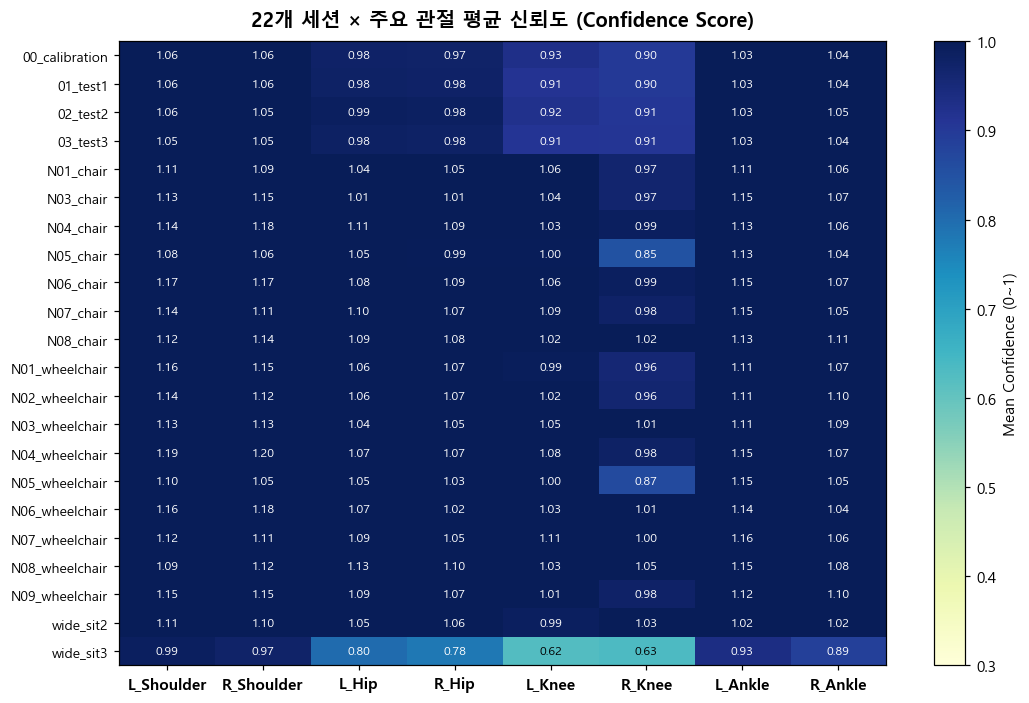

In [3]:
# 2. 그룹별 평균 통계 및 관절 감지 신뢰도(Confidence) 히트맵
print("📌 [그룹별 요약 통계]")
group_summary = summary_df.groupby("group")[
    ["frames", "duration_s", "L_valid_%", "R_valid_%", "L_norm_ROM", "R_norm_ROM", "L_angle_ROM_deg", "R_angle_ROM_deg"]
].mean().round(2)
print(group_summary.to_string())

# 관절별 평균 Confidence 행렬 생성
joint_ids = list(JOINT_NAMES.keys())
conf_matrix = []
labels_ordered = summary_df["label"].tolist()
for lbl in labels_ordered:
    c = records[lbl]["conf"][:, joint_ids]
    conf_matrix.append(np.nanmean(c, axis=0))
conf_df = pd.DataFrame(conf_matrix, index=labels_ordered, columns=[JOINT_NAMES[j] for j in joint_ids])

fig, ax = plt.subplots(figsize=(10, 6.5))
im = ax.imshow(conf_df.values, aspect="auto", cmap="YlGnBu", vmin=0.3, vmax=1.0)
ax.set_xticks(range(len(joint_ids)))
ax.set_xticklabels(conf_df.columns, fontweight="bold")
ax.set_yticks(range(len(labels_ordered)))
ax.set_yticklabels(labels_ordered, fontsize=9)
ax.set_title("22개 세션 × 주요 관절 평균 신뢰도 (Confidence Score)", fontsize=13, fontweight="bold", pad=10)

for i in range(len(labels_ordered)):
    for j in range(len(joint_ids)):
        val = conf_df.values[i, j]
        color = "white" if val > 0.7 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, fontsize=8)

plt.colorbar(im, ax=ax, label="Mean Confidence (0~1)")
plt.tight_layout()
plt.show()

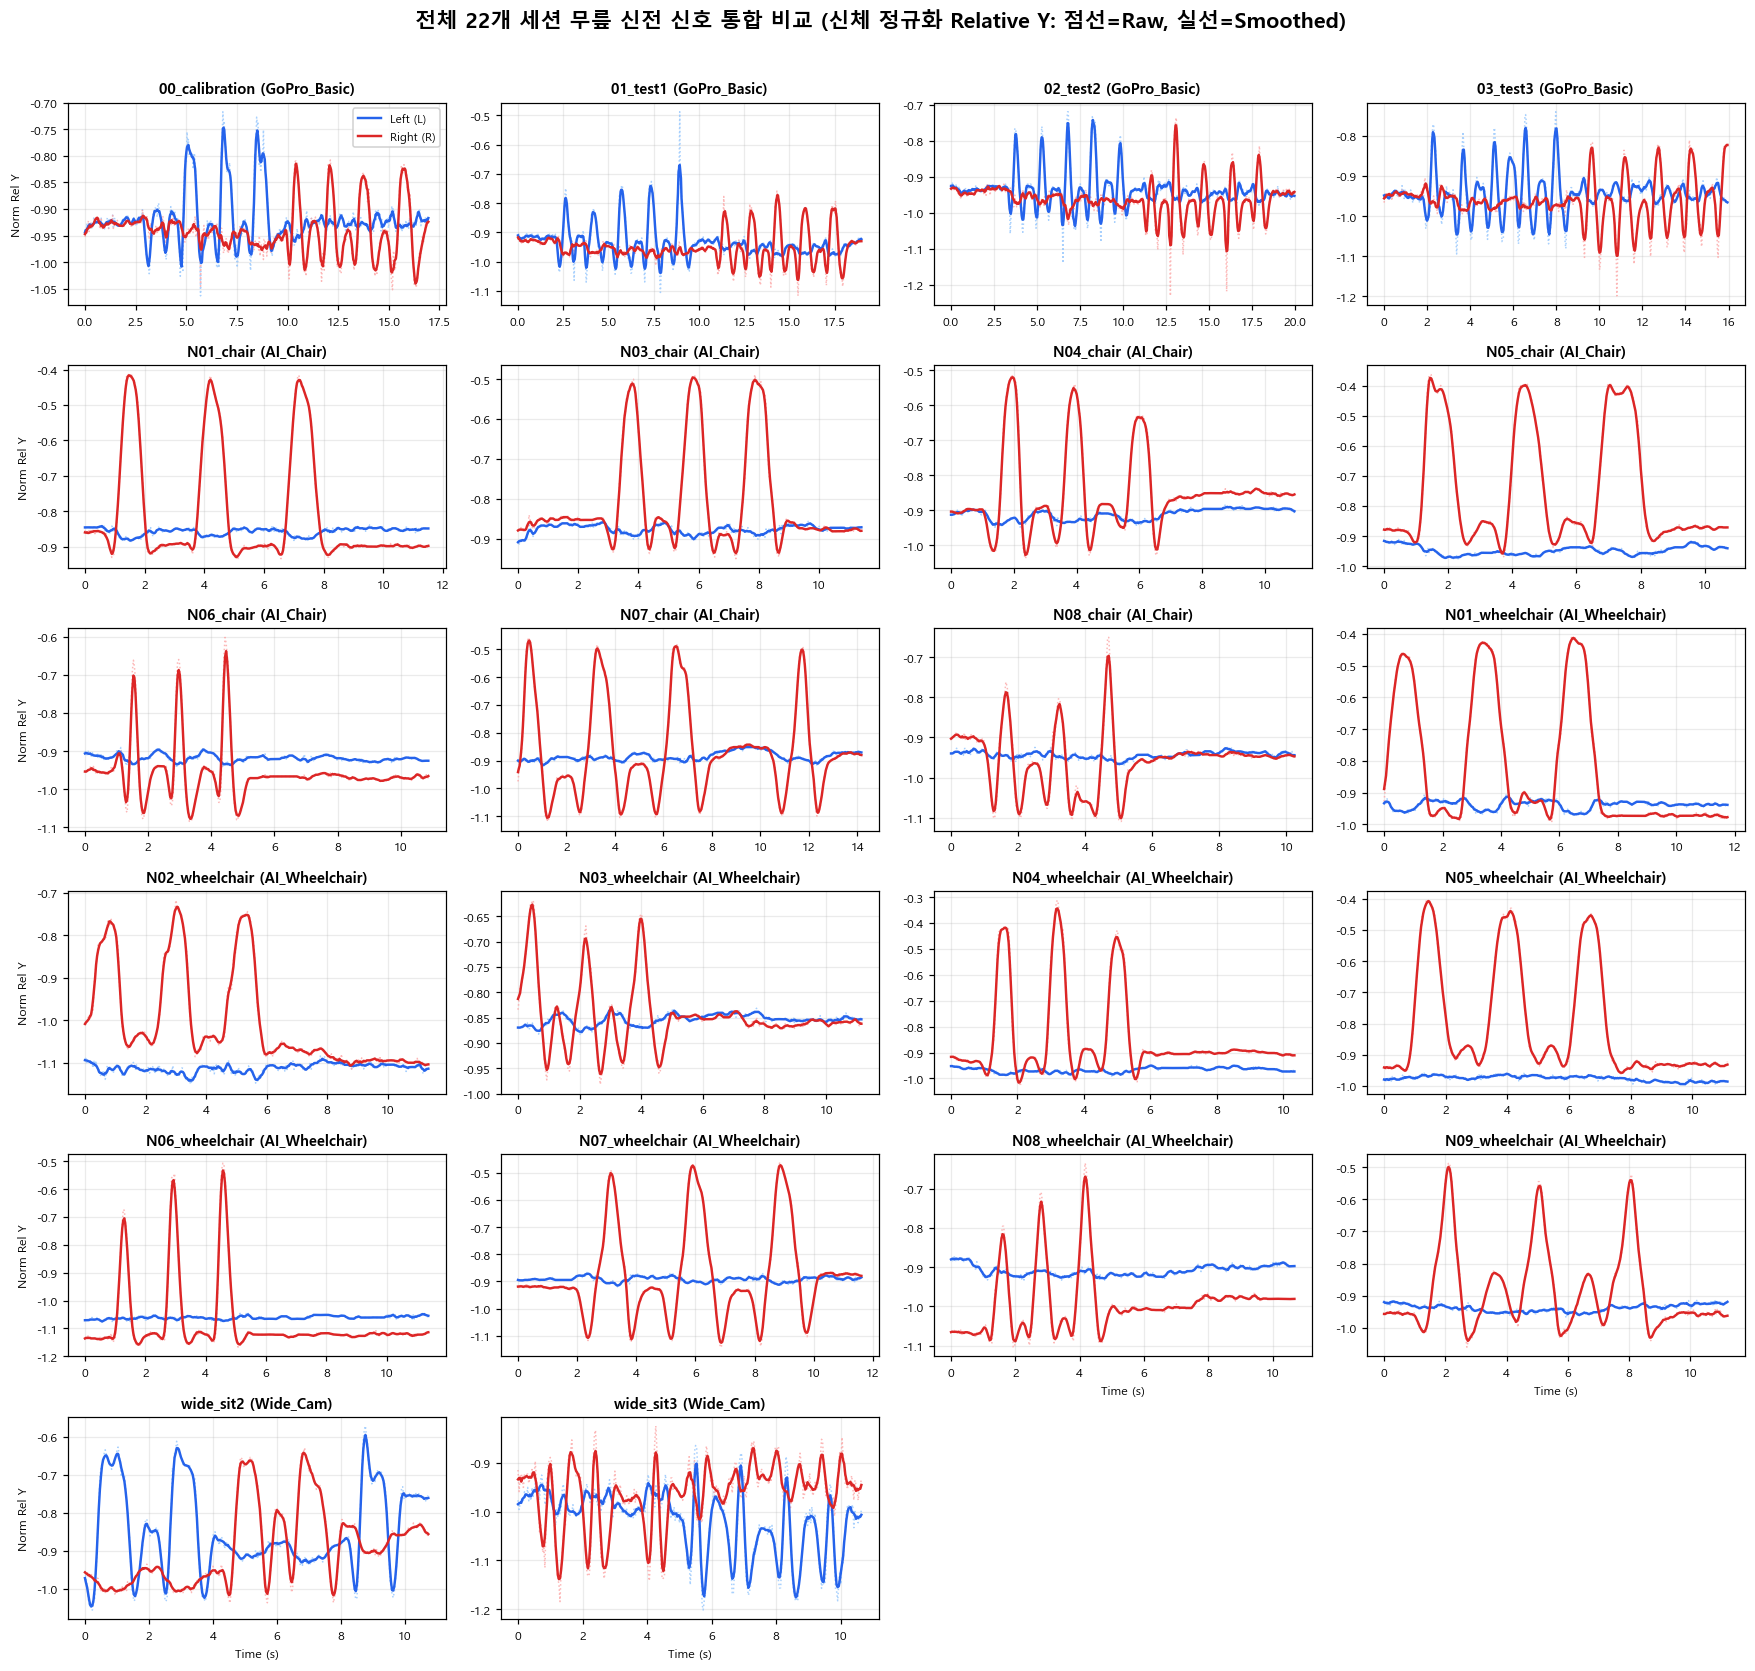

In [4]:
# 3. 22개 전체 세션 시계열 한눈에 보기 (신체 정규화 Relative Y: 원본 점선 vs 스무딩 실선)
labels_ordered = summary_df["label"].tolist()
n_sessions = len(labels_ordered)
ncols = 4
nrows = int(np.ceil(n_sessions / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 2.5), sharey=False)
axes = axes.flatten()

for idx, lbl in enumerate(labels_ordered):
    ax = axes[idx]
    rec = records[lbl]
    t = rec["timestamps"]
    fn_raw = rec["feat_norm"]
    fn_sm = rec["feat_norm_sm"]

    # 원본(점선) + 스무딩(실선)
    ax.plot(t, fn_raw["left_rel_y"], color="#93c5fd", ls=":", lw=1.0, alpha=0.8)
    ax.plot(t, fn_raw["right_rel_y"], color="#fca5a5", ls=":", lw=1.0, alpha=0.8)
    ax.plot(t, fn_sm["left_rel_y"], color="#2563eb", lw=1.6, label="Left (L)")
    ax.plot(t, fn_sm["right_rel_y"], color="#dc2626", lw=1.6, label="Right (R)")

    ax.set_title(f"{lbl} ({rec['group'][2:]})", fontsize=9.5, fontweight="bold")
    ax.grid(True, alpha=0.25)
    ax.tick_params(labelsize=8)
    if idx % ncols == 0:
        ax.set_ylabel("Norm Rel Y", fontsize=8)
    if idx >= n_sessions - ncols:
        ax.set_xlabel("Time (s)", fontsize=8)
    if idx == 0:
        ax.legend(loc="upper right", fontsize=7.5, framealpha=0.9)

for idx in range(n_sessions, len(axes)):
    axes[idx].axis("off")

fig.suptitle("전체 22개 세션 무릎 신전 신호 통합 비교 (신체 정규화 Relative Y: 점선=Raw, 실선=Smoothed)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

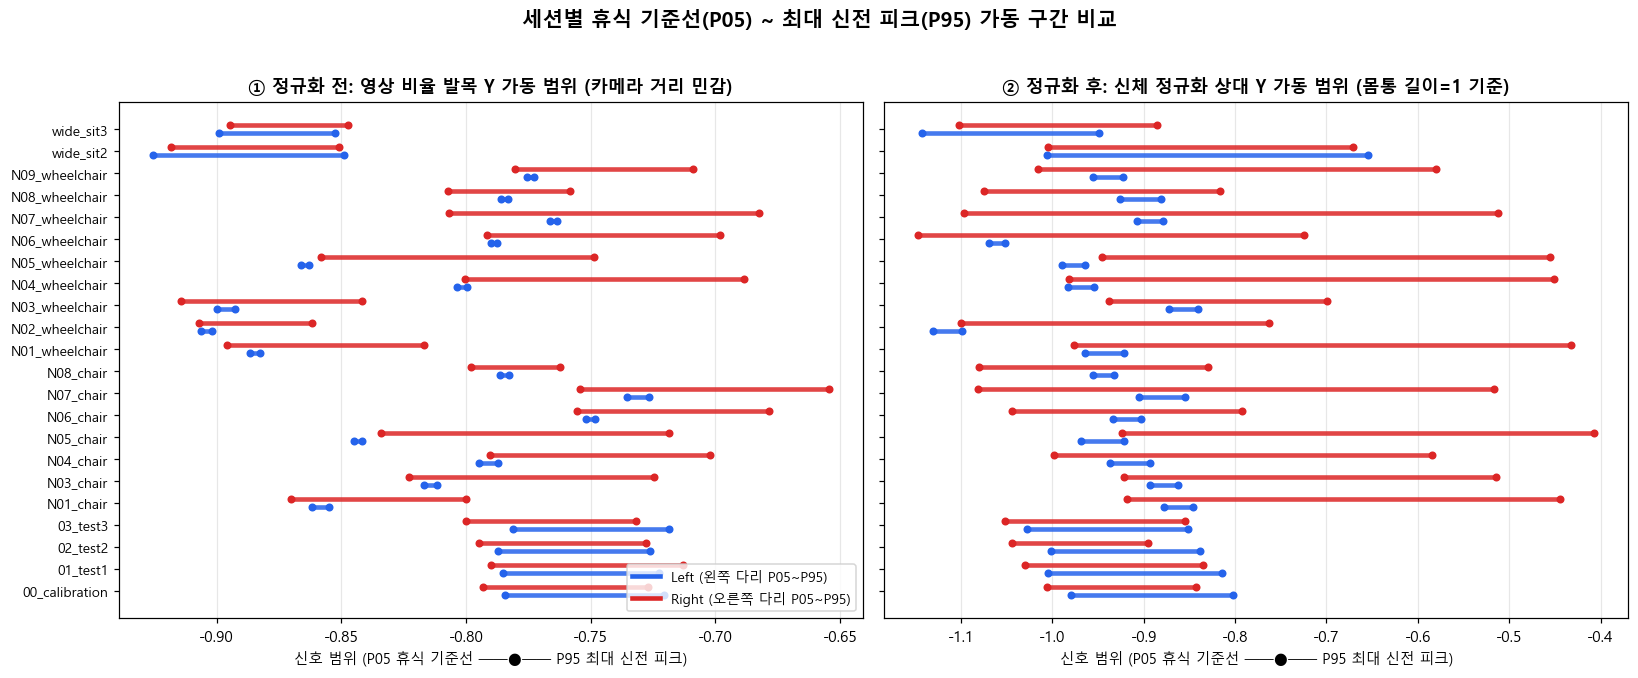

In [5]:
# 4. 정규화 전(영상 비율 Ankle Y) vs 정규화 후(신체 정규화 Relative Y) 가동 범위(ROM: P05 ~ P95) 비교
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
y_pos = np.arange(len(summary_df))
labels_ordered = summary_df["label"].tolist()

for ax_i, (mode_title, feat_key, sig_name) in enumerate([
    ("① 정규화 전: 영상 비율 발목 Y 가동 범위 (카메라 거리 민감)", "feat_ratio_sm", "ankle_y"),
    ("② 정규화 후: 신체 정규화 상대 Y 가동 범위 (몸통 길이=1 기준)", "feat_norm_sm", "rel_y"),
]):
    ax = axes[ax_i]
    for i, lbl in enumerate(labels_ordered):
        rec = records[lbl]
        for side, color, offset in (("left", "#2563eb", -0.18), ("right", "#dc2626", +0.18)):
            arr = rec[feat_key][f"{side}_{sig_name}"]
            valid = arr[np.isfinite(arr)]
            if len(valid) >= 5:
                p05, p50, p95 = np.percentile(valid, [5, 50, 95])
                ax.plot([p05, p95], [i + offset, i + offset], color=color, lw=3.0, alpha=0.85)
                ax.scatter([p05, p95], [i + offset, i + offset], color=color, s=18, zorder=3)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels_ordered, fontsize=9)
    ax.invert_yaxis()
    ax.set_title(mode_title, fontsize=11.5, fontweight="bold")
    ax.grid(True, axis="x", alpha=0.3)
    ax.set_xlabel("신호 범위 (P05 휴식 기준선 ──●── P95 최대 신전 피크)", fontsize=9.5)

# 범례 표시
axes[0].plot([], [], color="#2563eb", lw=3, label="Left (왼쪽 다리 P05~P95)")
axes[0].plot([], [], color="#dc2626", lw=3, label="Right (오른쪽 다리 P05~P95)")
axes[0].legend(loc="lower right", fontsize=9)

plt.suptitle("세션별 휴식 기준선(P05) ~ 최대 신전 피크(P95) 가동 구간 비교", fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

📌 [전체 프레임 기준 측정 피처 후보군 상관계수 행렬]
                norm_rel_y  norm_ankle_y  ratio_ankle_y  knee_angle_deg  norm_shin_len
norm_rel_y           1.000         0.866          0.243          -0.012         -0.999
norm_ankle_y         0.866         1.000          0.315          -0.144         -0.866
ratio_ankle_y        0.243         0.315          1.000          -0.070         -0.238
knee_angle_deg      -0.012        -0.144         -0.070           1.000          0.005
norm_shin_len       -0.999        -0.866         -0.238           0.005          1.000


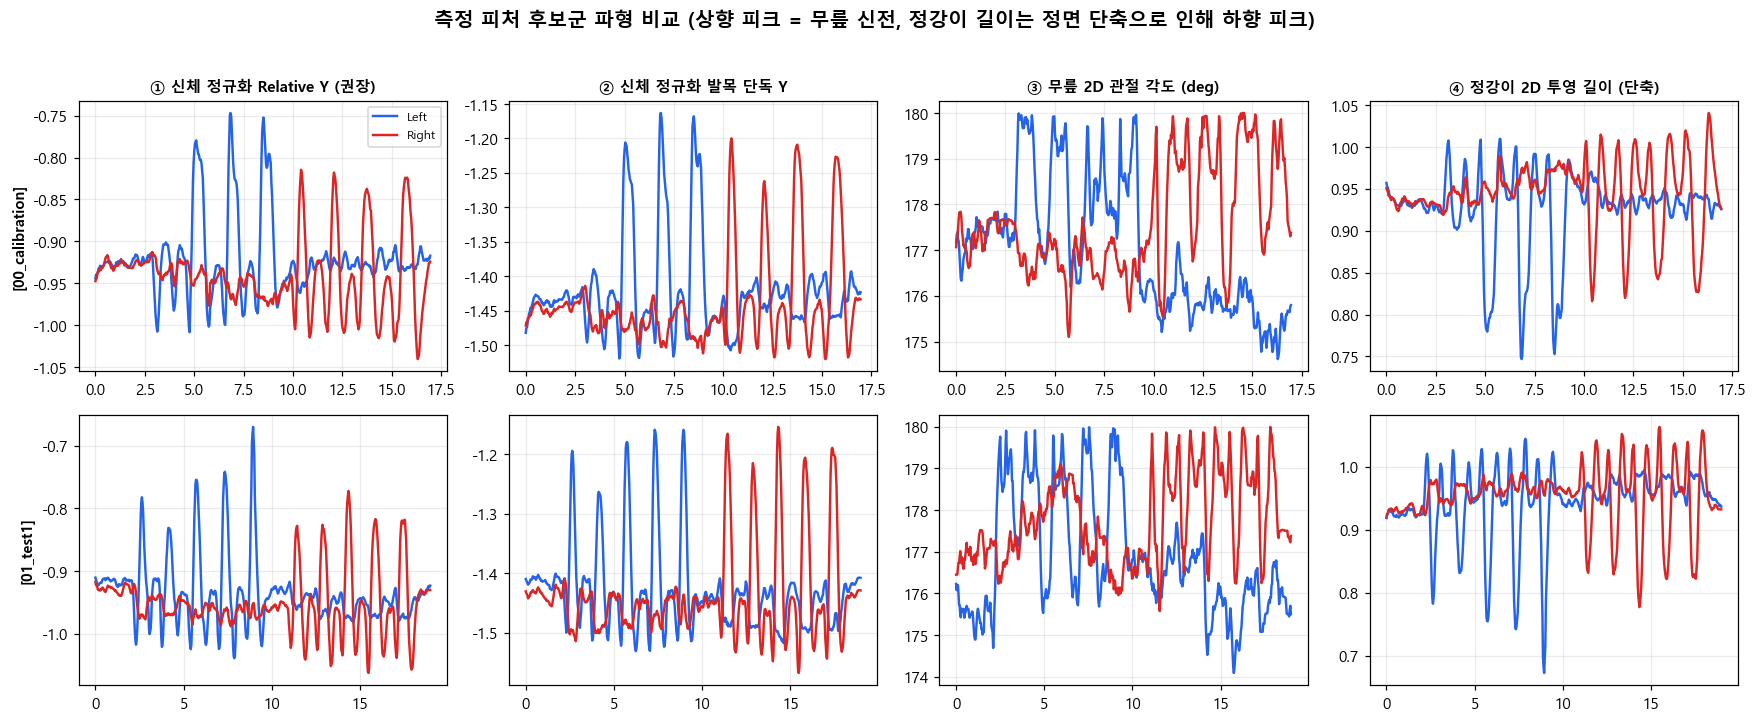

In [6]:
# 5. 측정 피처 후보군 비교 (Relative Y vs 발목 단독 Y vs 정강이 2D 길이 vs 무릎 3점 각도)
# 모든 프레임의 데이터를 하나로 합쳐 피처 간 상관계수 및 특성을 확인합니다.
all_feat_rows = []
for lbl, rec in records.items():
    fn = rec["feat_norm_sm"]
    fr = rec["feat_ratio_sm"]
    for side in ("left", "right"):
        df_s = pd.DataFrame({
            "session": lbl,
            "group": rec["group"],
            "side": side,
            "norm_rel_y": fn[f"{side}_rel_y"],
            "norm_ankle_y": fn[f"{side}_ankle_y"],
            "norm_shin_len": fn[f"{side}_shin_len"],
            "ratio_ankle_y": fr[f"{side}_ankle_y"],
            "knee_angle_deg": fr[f"{side}_angle_deg"],
        })
        all_feat_rows.append(df_s)

all_feat_df = pd.concat(all_feat_rows, ignore_index=True).dropna()
corr_cols = ["norm_rel_y", "norm_ankle_y", "ratio_ankle_y", "knee_angle_deg", "norm_shin_len"]
corr_mat = all_feat_df[corr_cols].corr()
print("📌 [전체 프레임 기준 측정 피처 후보군 상관계수 행렬]")
print(corr_mat.round(3).to_string())

# 대표 세션 2개(00_calibration vs N01_chair)에서 4가지 피처 파형 비교
sample_labels = [lbl for lbl in ("00_calibration", "01_test1", "N01_chair", "N01_wheelchair") if lbl in records][:2]
fig, axes = plt.subplots(len(sample_labels), 4, figsize=(16, 3.2 * len(sample_labels)), sharex="row")
if len(sample_labels) == 1:
    axes = np.expand_dims(axes, 0)

feature_specs = [
    ("feat_norm_sm", "rel_y", "① 신체 정규화 Relative Y (권장)"),
    ("feat_norm_sm", "ankle_y", "② 신체 정규화 발목 단독 Y"),
    ("feat_ratio_sm", "angle_deg", "③ 무릎 2D 관절 각도 (deg)"),
    ("feat_norm_sm", "shin_len", "④ 정강이 2D 투영 길이 (단축)"),
]

for r_i, lbl in enumerate(sample_labels):
    rec = records[lbl]
    t = rec["timestamps"]
    for c_i, (f_group, f_name, title) in enumerate(feature_specs):
        ax = axes[r_i, c_i]
        ax.plot(t, rec[f_group][f"left_{f_name}"], color="#2563eb", lw=1.6, label="Left")
        ax.plot(t, rec[f_group][f"right_{f_name}"], color="#dc2626", lw=1.6, label="Right")
        if r_i == 0:
            ax.set_title(title, fontsize=10, fontweight="bold")
        if c_i == 0:
            ax.set_ylabel(f"[{lbl}]", fontsize=9.5, fontweight="bold")
        ax.grid(True, alpha=0.25)
        if r_i == 0 and c_i == 0:
            ax.legend(loc="upper right", fontsize=8)

plt.suptitle("측정 피처 후보군 파형 비교 (상향 피크 = 무릎 신전, 정강이 길이는 정면 단축으로 인해 하향 피크)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

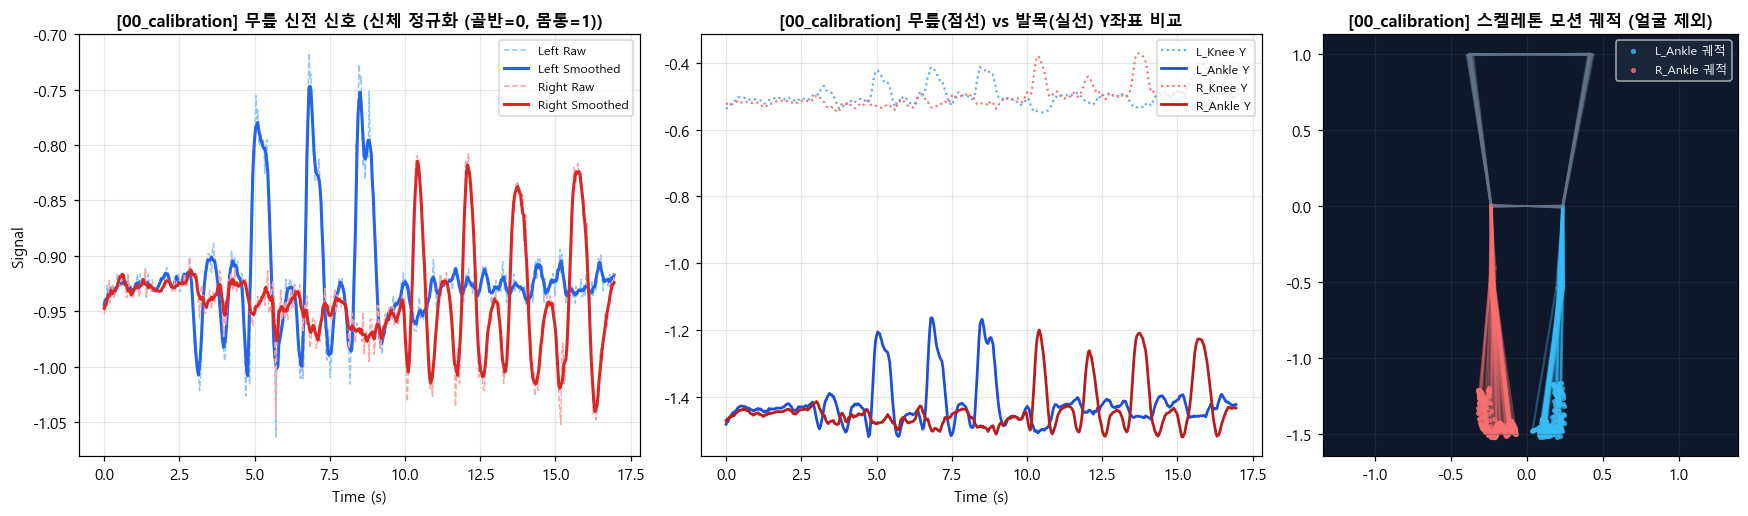

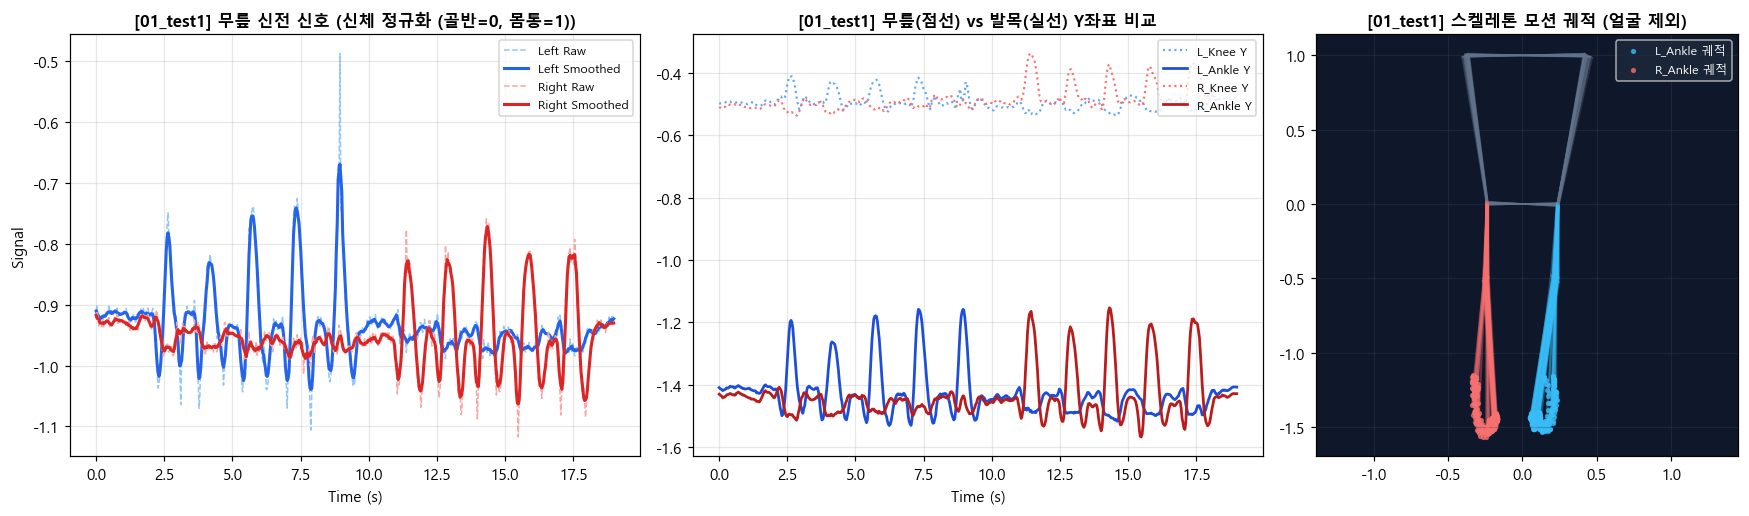

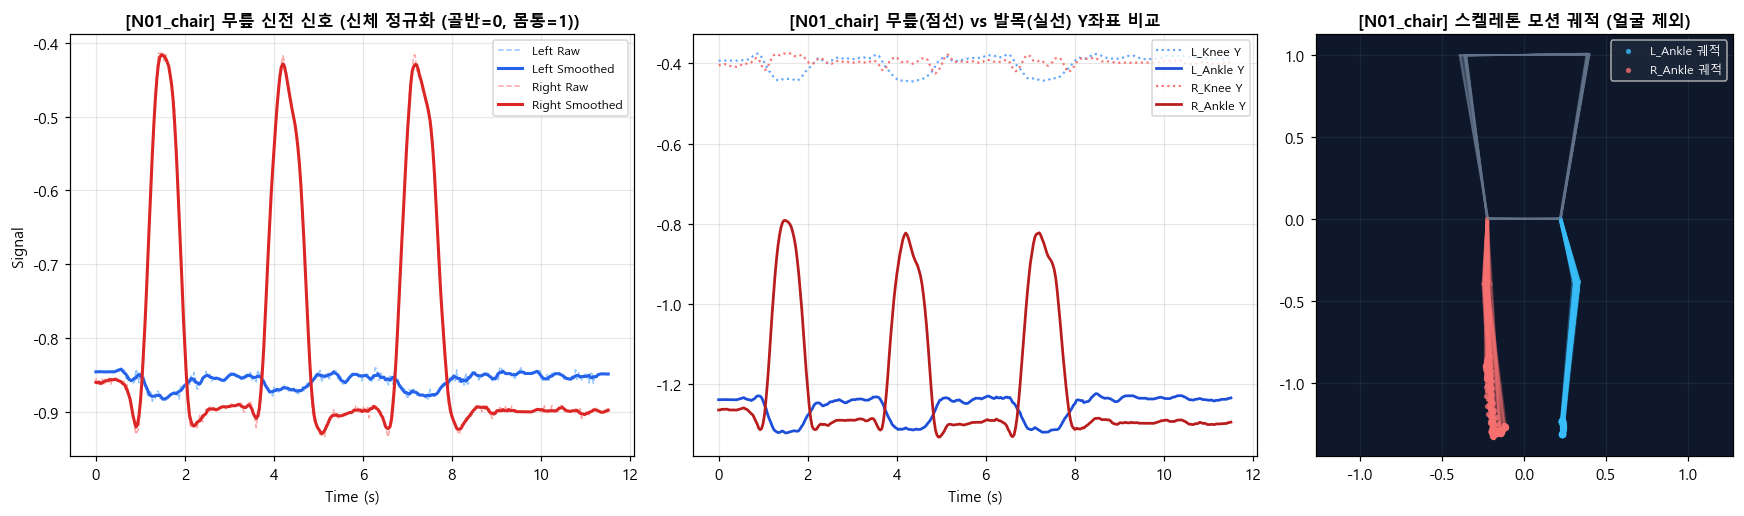

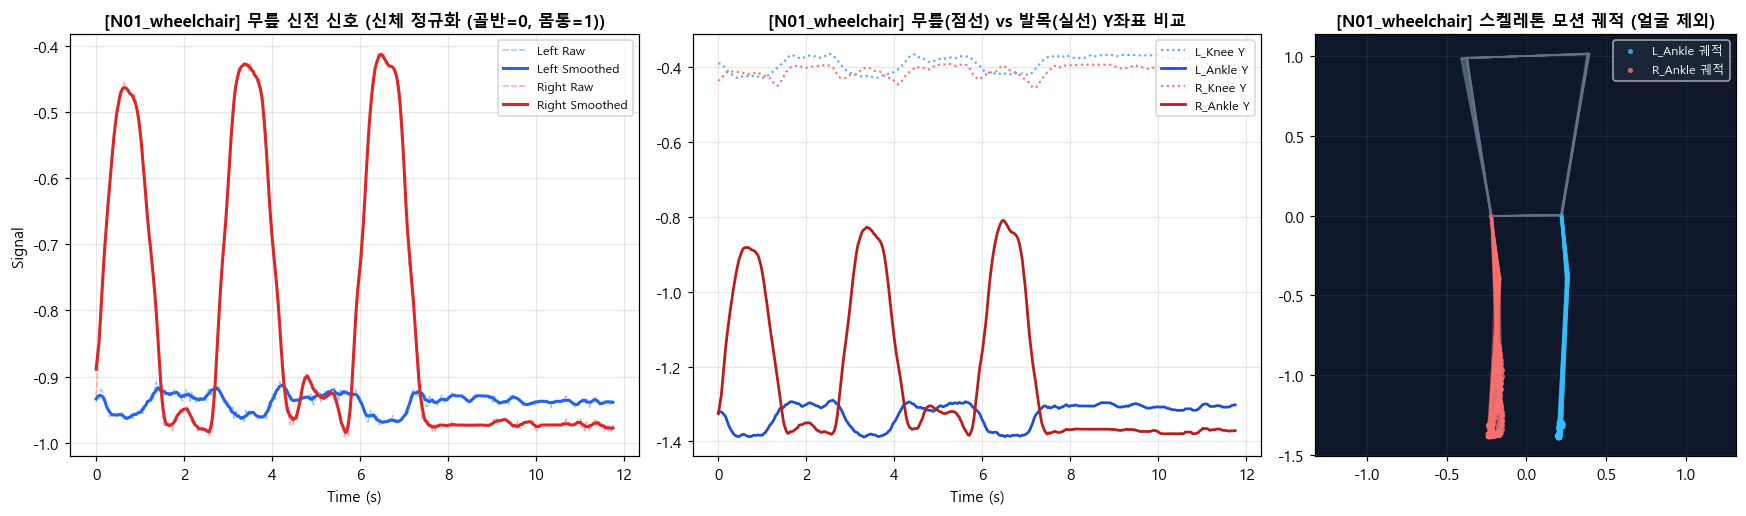

In [7]:
# 6. 개별 세션 정밀 분석 및 하체 스켈레톤 궤적(검은 배경 모션 팬) 확인 함수
def plot_session_detail(query: str = "00_calibration", use_norm: bool = True):
    """라벨 또는 파일명 일부(예: 'calibration', 'test1', 'N01_chair', 'sit2')로 세션을 찾아 상세 그래프와 스켈레톤 궤적을 그립니다."""
    matched = [lbl for lbl in records if query.lower() in lbl.lower() or query.lower() in records[lbl]["source_video"].lower()]
    if not matched:
        print(f"⚠️ '{query}'와 일치하는 세션을 찾지 못했습니다. 사용 가능한 라벨: {list(records.keys())}")
        return
    lbl = matched[0]
    rec = records[lbl]
    t = rec["timestamps"]
    f_raw = rec["feat_norm"] if use_norm else rec["feat_ratio"]
    f_sm = rec["feat_norm_sm"] if use_norm else rec["feat_ratio_sm"]
    coords_sm = rec["norm_smooth"] if use_norm else rec["ratio_smooth"]
    coord_label = "신체 정규화 (골반=0, 몸통=1)" if use_norm else "영상 비율 (0~1)"

    fig = plt.figure(figsize=(16, 4.8))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.35, 1.35, 1.0])

    # (1) 좌/우 무릎 신전 신호 (Raw vs Smoothed)
    ax1 = fig.add_subplot(gs[0])
    sig_key = "rel_y" if use_norm else "ankle_y"
    ax1.plot(t, f_raw[f"left_{sig_key}"], color="#93c5fd", ls="--", lw=1.0, label="Left Raw")
    ax1.plot(t, f_sm[f"left_{sig_key}"], color="#2563eb", lw=2.0, label="Left Smoothed")
    ax1.plot(t, f_raw[f"right_{sig_key}"], color="#fca5a5", ls="--", lw=1.0, label="Right Raw")
    ax1.plot(t, f_sm[f"right_{sig_key}"], color="#dc2626", lw=2.0, label="Right Smoothed")
    ax1.set_title(f"[{lbl}] 무릎 신전 신호 ({coord_label})", fontsize=11, fontweight="bold")
    ax1.set_xlabel("Time (s)")
    ax1.set_ylabel("Signal")
    ax1.grid(True, alpha=0.3)
    ax1.legend(loc="upper right", fontsize=8)

    # (2) 무릎 및 발목 개별 Y좌표 추이
    ax2 = fig.add_subplot(gs[1])
    ax2.plot(t, f_sm["left_knee_y"], color="#60a5fa", ls=":", lw=1.4, label="L_Knee Y")
    ax2.plot(t, f_sm["left_ankle_y"], color="#1d4ed8", lw=1.8, label="L_Ankle Y")
    ax2.plot(t, f_sm["right_knee_y"], color="#f87171", ls=":", lw=1.4, label="R_Knee Y")
    ax2.plot(t, f_sm["right_ankle_y"], color="#b91c1c", lw=1.8, label="R_Ankle Y")
    ax2.set_title(f"[{lbl}] 무릎(점선) vs 발목(실선) Y좌표 비교", fontsize=11, fontweight="bold")
    ax2.set_xlabel("Time (s)")
    ax2.grid(True, alpha=0.3)
    ax2.legend(loc="upper right", fontsize=8)

    # (3) 검은 배경 하체 스켈레톤 모션 궤적 팬(Motion Fan)
    ax3 = fig.add_subplot(gs[2])
    ax3.set_facecolor("#0f172a")
    step = max(1, len(t) // 45)
    for f_i in range(0, len(t), step):
        pts = coords_sm[f_i]
        # 상체(어깨-골반)
        for a, b in ((5, 6), (11, 12), (5, 11), (6, 12)):
            if np.isfinite(pts[[a, b], :2]).all():
                ax3.plot(pts[[a, b], 0], pts[[a, b], 1], color="#64748b", lw=1.0, alpha=0.25)
        # 왼쪽 다리(파랑), 오른쪽 다리(빨강)
        for a, b in ((11, 13), (13, 15)):
            if np.isfinite(pts[[a, b], :2]).all():
                ax3.plot(pts[[a, b], 0], pts[[a, b], 1], color="#38bdf8", lw=1.5, alpha=0.35)
        for a, b in ((12, 14), (14, 16)):
            if np.isfinite(pts[[a, b], :2]).all():
                ax3.plot(pts[[a, b], 0], pts[[a, b], 1], color="#f87171", lw=1.5, alpha=0.35)

    # 발목 궤적 점 찍기
    ax3.scatter(coords_sm[:, 15, 0], coords_sm[:, 15, 1], color="#38bdf8", s=6, alpha=0.7, label="L_Ankle 궤적")
    ax3.scatter(coords_sm[:, 16, 0], coords_sm[:, 16, 1], color="#f87171", s=6, alpha=0.7, label="R_Ankle 궤적")
    if not use_norm:
        ax3.invert_yaxis()
    ax3.set_aspect("equal", adjustable="datalim")
    ax3.set_title(f"[{lbl}] 스켈레톤 모션 궤적 (얼굴 제외)", fontsize=11, fontweight="bold")
    ax3.legend(loc="upper right", fontsize=8, facecolor="#1e293b", labelcolor="white")
    ax3.grid(True, color="#334155", alpha=0.35)

    plt.tight_layout()
    plt.show()

# 예시 실행: GoPro 기본 영상 및 AI 데이터셋 의자/휠체어 비교
plot_session_detail("00_calibration", use_norm=True)
plot_session_detail("01_test1", use_norm=True)
plot_session_detail("N01_chair", use_norm=True)
plot_session_detail("N01_wheelchair", use_norm=True)